# Part 1 · Bank notes classification

In real world, missing a fake banknote is costly for the bank, but flagging a real note as fake also creates work. As the first part, 4 classification models will be trained and tested for results.


In [1]:
import csv
import gc
import hashlib
import json
import random
import time
from pathlib import Path
from tempfile import TemporaryDirectory

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import display
from matplotlib.figure import Figure
from torch import nn
from torch.utils.data import DataLoader, Dataset
from torchvision.models import (
    EfficientNet_V2_S_Weights, ResNet18_Weights, efficientnet_v2_s, resnet18,
)

import timm

# Choose which experiments to run when executing the notebook.
RUN_COMPARISON = True  # Train when no completed comparison is available.
RUN_DEMOS = False       # Optional short CNN fit and pilot evaluation.
RECHECK_RANKING = False  # Optional replay of the four checkpoints across both test sets.

In [2]:
DATA = Path("dataset_archive_course_v3")
PILOT_DATA = Path("dataset_archive_pilot_v2")
RESNET = Path("runs/archive_pilot_v2/resnet18/best.pt")
COMPARISON = Path("runs/course_models_archive_v3")
SEED = 42
BATCH_SIZE = 32
DEMO_EPOCHS = 3
EPOCHS = 30
LR = 1e-3
CLASS_NAMES = ["fake money", "OR money", "not a banknote"]
CLASS_TO_IDX = {name: i for i, name in enumerate(CLASS_NAMES)}
DISPLAY_NAMES = {"fake money": "Fake Money", "OR money": "Real Money", "not a banknote": "Not a Banknote"}
TRANSFER_MODELS = ("resnet18", "efficientnet_v2_s", "dinov3_vits16")
DINO_TIMM_MODEL = "vit_small_patch16_dinov3.lvd1689m"


MODEL_NAMES = {"cnn": "CNN", "resnet18": "ResNet18", "efficientnet_v2_s": "EfficientNetV2-S",
               "dinov3_vits16": "DINOv3 ViT-S/16"}
METRICS = ["accuracy", "balanced_accuracy", "fake_recall", "fake_fnr", "fake_precision",
           "real_false_alarm_rate", "not_banknote_recall", "not_banknote_as_fake_rate"]


def sha256(path):
    """Hash a file's bytes to identify the exact dataset manifest or checkpoint used in a run."""
    return hashlib.sha256(Path(path).read_bytes()).hexdigest()


def read_rgb(path):
    """Load a photograph as RGB, keeping the stored pixel orientation."""
    bgr = cv2.imread(str(path), cv2.IMREAD_COLOR | cv2.IMREAD_IGNORE_ORIENTATION)
    if bgr is None and Path(path).suffix.lower() == ".avif":
        # Some OpenCV builds decode AVIF only through the FFmpeg backend.
        reader = cv2.VideoCapture(str(path), cv2.CAP_FFMPEG)
        _, bgr = reader.read()
        reader.release()
    return cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)

## 1. Image category

The following part shows the 3 categories for this project: real, fake, and not a bank note. Numbers of test/val/train are shown below with training images and paths as examples.

split,train,val,test
label,,,
Fake Money,83,17,24
Not a Banknote,22,4,4
Real Money,82,17,25


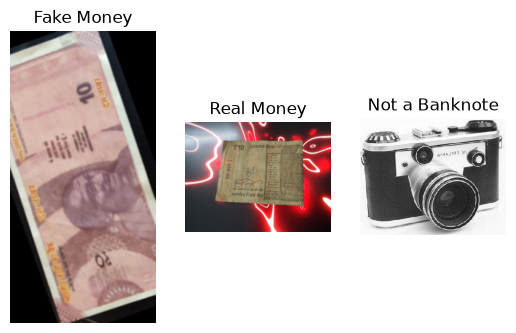

,label,split_path
0,Fake Money,train/fake money/10_3013738dc9732936.jpeg
124,Real Money,train/OR money/10_9b1ec45648e42474.jpg
248,Not a Banknote,train/not a banknote/camera_image_0045.jpg


In [9]:
def show_photos(files, captions):
    plt.figure()
    for i, (path, caption) in enumerate(zip(files, captions), start=1):
        plt.subplot(1, len(files), i)
        plt.imshow(read_rgb(DATA / path))
        plt.title(caption)
        plt.axis("off")
    plt.show()


paths = pd.read_csv(DATA / "image_paths.csv", usecols=["split", "label", "split_path"])
paths["label"] = paths["label"].map(DISPLAY_NAMES)
names = list(DISPLAY_NAMES.values())
display(pd.crosstab(paths["label"], paths["split"])[["train", "val", "test"]])

examples = paths[paths["split"] == "train"].drop_duplicates("label")
show_photos(examples["split_path"], examples["label"])
display(examples[["label", "split_path"]])

## 2. Compare the models on the same 53 test photographs

The CNN learns from scratch on 64 × 64 images. ResNet18, EfficientNetV2-S and DINOv3 train a classification head on frozen pretrained features at 224 × 224. All four use full-frame letterboxing, Adam, the same split and a 30-epoch limit. The lowest validation loss selects each checkpoint.

All models saw the same 53 test images. The dataset labels 24 as fake, 25 as real and 4 as non-banknotes.

| Table column | How to read it |
| --- | --- |
| Accuracy | Out of all 53 images, what percentage got the correct label? Higher is better. |
| Fake recall | Out of the 24 images labelled fake, what percentage did the model catch? Higher is better. |
| Missed fakes | Out of those same 24 images, what percentage did the model call real or non-banknote? This is 100% minus fake recall. Lower is better. |
| Real flagged fake | Out of the 25 images labelled real, what percentage did the model call fake? Lower means fewer false alarms. |
| Fake precision | Of all the images the model called fake, what percentage had a fake label in the dataset? Higher means a fake alert is more often correct. |
| Seconds per fit | Average time in seconds to train the model once. A smaller number means faster training. |

For example, in the EfficientNetV2-S run with seed 42, the model caught 23 of the 24 fake-labelled images. It also flagged 4 real-labelled images. Its fake recall was 23/24 (95.8%), and its fake precision was 23/27 (85.2%).

The table averages three training runs with seeds 42, 43 and 44. A fake recall of 93.1 ± 2.4% means the average was 93.1% and the sample standard deviation across runs was 2.4 percentage points. A smaller spread means the runs gave more similar results on these images.

In the plots below, validation loss measures how well the predicted probabilities fit the validation labels (lower is better). Non-banknote recall is the percentage of the 4 non-banknote test images correctly identified. In each confusion matrix, read across a row for a dataset label and down a column for a prediction. For example, the Real row and Fake column shows false alarms. Counts can be fractional because the plot averages three runs.

,Accuracy,Fake recall,Missed fakes,Real flagged fake,Fake precision,Seconds per fit
Model,,,,,,
CNN,78.0 ± 2.9%,86.1 ± 2.4%,13.9 ± 2.4%,29.3 ± 8.3%,71.6 ± 4.8%,70.3
ResNet18,86.8 ± 3.3%,88.9 ± 8.7%,11.1 ± 8.7%,17.3 ± 2.3%,83.1 ± 1.3%,95.5
EfficientNetV2-S,90.6 ± 0.0%,93.1 ± 2.4%,6.9 ± 2.4%,13.3 ± 2.3%,87.1 ± 1.6%,137.8
DINOv3 ViT-S/16,89.9 ± 1.1%,91.7 ± 0.0%,8.3 ± 0.0%,13.3 ± 2.3%,86.9 ± 2.0%,127.9


Figure: /Users/grz/Documents/dataai/CSC_51073_EP/project/Fake_Money_Detection/runs/course_models_archive_v3/comparison.png


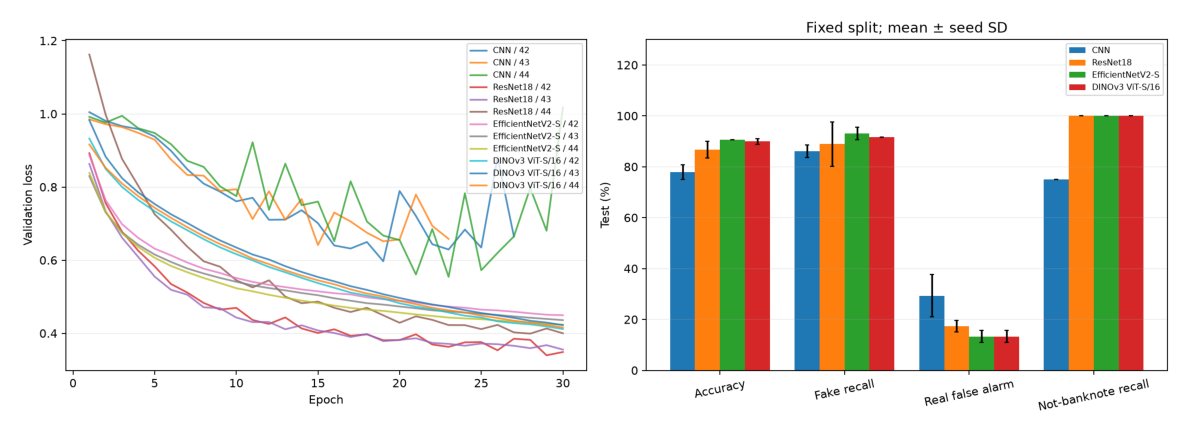

Figure: /Users/grz/Documents/dataai/CSC_51073_EP/project/Fake_Money_Detection/runs/course_models_archive_v3/confusion_matrices.png


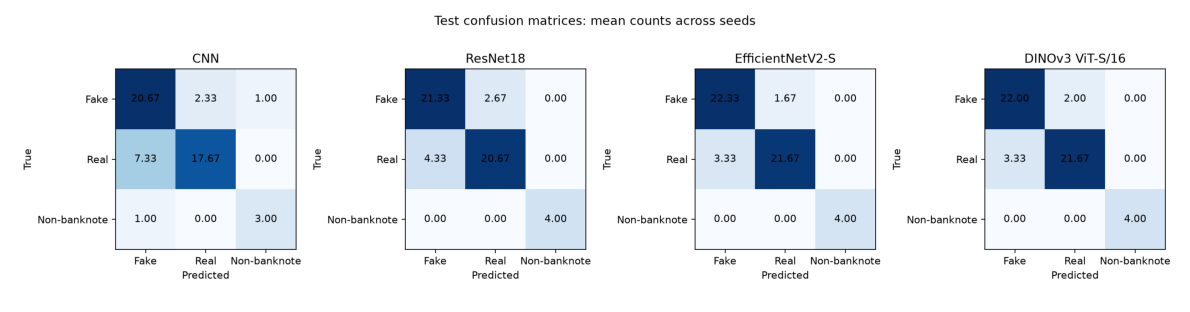

In [4]:
results_file = COMPARISON / "comparison.json"
results = json.loads(results_file.read_text()) if results_file.exists() else None
if results:
    assert results["protocol"]["manifest_sha256"] == sha256(DATA / "manifest.json")
    archs = results["protocol"]["models"]
    metrics = {"accuracy":"Accuracy", "fake_recall":"Fake recall", "fake_fnr":"Missed fakes",
               "real_false_alarm_rate":"Real flagged fake", "fake_precision":"Fake precision"}
    seconds = pd.DataFrame(results["runs"]).groupby("architecture")["training_seconds"].mean()
    table = []
    for arch in archs:
        row = {"Model": MODEL_NAMES[arch]}
        for key, title in metrics.items():
            stat = results["summary"]["test"][arch][key]
            mean, sd = stat["mean"], stat["sd"]
            if mean is None:
                row[title] = "n/a"
            elif sd is None:
                row[title] = f"{100 * mean:.1f}%"
            else:
                row[title] = f"{100 * mean:.1f} ± {100 * sd:.1f}%"
        row["Seconds per fit"] = round(seconds[arch], 1)
        table.append(row)
    display(pd.DataFrame(table).set_index("Model"))
    for name in ("comparison.png", "confusion_matrices.png"):
        print("Figure:", (COMPARISON / name).resolve())
        plt.figure(figsize=(12, 5))
        plt.imshow(read_rgb(COMPARISON / name))
        plt.axis("off")
        plt.tight_layout()
        plt.show()
else:
    print("Run the training appendix to generate the comparison, then replay Sections 2 and 3.")

### Check two photographs where the models disagree

On the expanded test set EfficientNetV2-S gained **4.17 percentage points in fake recall** over ResNet18 and lowered the real-note false-alarm rate by **4.00 points**. Against DINOv3 its recall gain was **1.39 points** and both flagged **13.33%** of real notes.

**Can two models have the same accuracy while missing different notes?** Use seed 42, where both EfficientNet and DINOv3 got 48 of 53 right. The first panel shows the first fake-labelled note in roster order that EfficientNet caught and DINOv3 missed. The second shows the reverse. Use the image paths to find the examples in the dataset folder. The table below also shows the CNN and ResNet18 predictions for the first six errors across the four models.

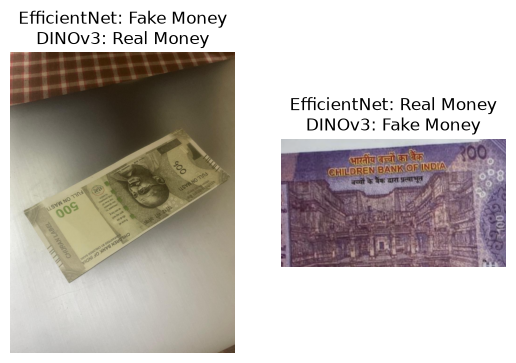

,label,EfficientNetV2-S,DINOv3 ViT-S/16
split_path,,,
test/fake money/500_12ede66445aa3822.jpg,Fake Money,Fake Money,Real Money
test/fake money/100_4b6f91bfcd036823.png,Fake Money,Real Money,Fake Money


,label,CNN,ResNet18,EfficientNetV2-S,DINOv3 ViT-S/16
split_path,,,,,
test/fake money/100_4b6f91bfcd036823.png,Fake Money,Fake Money,Fake Money,Real Money,Fake Money
test/fake money/500_92c7017763de5a1b.jpg,Fake Money,Real Money,Real Money,Fake Money,Fake Money
test/fake money/500_12ede66445aa3822.jpg,Fake Money,Real Money,Fake Money,Fake Money,Real Money
test/fake money/500_c8ec7e37f9739637.jpg,Fake Money,Fake Money,Fake Money,Fake Money,Real Money
test/fake money/2000_6ed5ae16eb6d0ce8.png,Fake Money,Not a Banknote,Fake Money,Fake Money,Fake Money
test/OR money/100_f5a765f1ce4bb123.jpg,Real Money,Fake Money,Real Money,Real Money,Real Money


In [5]:
if results:
    cases = paths[paths["split"] == "test"].set_index("split_path").copy()
    for run in results["runs"]:
        if run["seed"] == 42:
            cases[MODEL_NAMES[run["architecture"]]] = {
                Path(*Path(p["path"]).parts[-3:]).as_posix(): names[p["predicted_label"]]
                for p in run["test_predictions"]}
    model_cols = [MODEL_NAMES[m] for m in archs]
    assert cases[model_cols].notna().all().all()
    fake = cases[cases["label"] == "Fake Money"]
    efficient = fake["EfficientNetV2-S"] == "Fake Money"
    dino = fake["DINOv3 ViT-S/16"] == "Fake Money"
    pair = pd.concat([fake[efficient & ~dino].head(1), fake[dino & ~efficient].head(1)])
    if not pair.empty:
        captions = ["EfficientNet: " + e + "\nDINOv3: " + d
                    for e, d in zip(pair["EfficientNetV2-S"], pair["DINOv3 ViT-S/16"])]
        show_photos(pair.index, captions)
    disagreements = cases[model_cols].ne(cases["label"], axis=0).any(axis=1)
    display(pair[["label", "EfficientNetV2-S", "DINOv3 ViT-S/16"]])
    display(cases.loc[disagreements, ["label", *model_cols]].head(6))

## 3. Why did the model ranking change?

The original four-model comparison used **65 train / 12 validation / 12 test**. Each test class contained four images. One more correct prediction changed single-seed accuracy by **8.33 percentage points**. The expanded comparison used **187 / 38 / 53**, with **44 of 53 test images** from the 500- and 2000-rupee folders. Four non-banknote test photos occur in both sets. The 18-image pilot used in the CAM lab is a third, separate experiment.

Read the table from left to right. The first two columns score different fits on the same old test set. The last two columns score **the very same expanded-data checkpoints** on different test sets. Every entry averages seeds 42, 43 and 44. [Original completed-run log](runs/course_models_archive_v3/rank_check/original_four_model_run.log) · [Checkpoint hashes and paired predictions](runs/course_models_archive_v3/rank_check/fixed_checkpoint_test.json)

In [6]:
rank_dir = COMPARISON / "rank_check"
if results and (rank_dir / "fixed_checkpoint_test.json").exists():
    rank = json.loads((rank_dir / "fixed_checkpoint_test.json").read_text())
    assert sha256(rank_dir / "original_four_model_run.log") == rank["historical_log_sha256"]
    assert all(sha256(Path(folder) / "manifest.json") == digest
               for folder, digest in rank["manifests"].items())
    assert {(r["architecture"], r["seed"], r["checkpoint_sha256"]) for r in results["runs"]} == {
        (r["model"], r["seed"], r["checkpoint_hash"]) for r in rank["runs"]}
    accuracy = pd.DataFrame({
        "Original fit → old test": {m: rank["historical"][m]["accuracy"]["mean"] for m in archs},
        "Expanded fit → old test": {m: rank["fixed_checkpoint_means"][m]["old"]["accuracy"] for m in archs},
        "Expanded fit → new test": {m: rank["fixed_checkpoint_means"][m]["new"]["accuracy"] for m in archs}})
    display((100 * accuracy.rename(index=MODEL_NAMES)).round(2).rename_axis("Accuracy (%)"))

,Original fit → old test,Expanded fit → old test,Expanded fit → new test
Accuracy (%),,,
CNN,55.56,77.78,77.99
ResNet18,83.33,63.89,86.79
EfficientNetV2-S,80.56,66.67,90.57
DINOv3 ViT-S/16,88.89,61.11,89.94


**Read across one row first.** DINOv3 scored 88.89% in the original run. After fitting on the expanded data it scored 61.11% on those same 12 photographs. With those expanded weights held fixed, it scored 89.94% on the new 53. Changing the fit had already reversed the order of EfficientNet and DINOv3 on the old images. Training photographs, validation images and device (CPU to MPS) changed together.

**Now count the difference in photographs.** Across the three seeds, EfficientNet and DINOv3 got 48 vs 48, 48 vs 47 and 48 vs 48 correct. Over those repeated predictions EfficientNet gained two correct decisions on 500-rupee images and two on 2000-rupee images, and lost three on 100-rupee images. That leaves **one additional correct decision**. There were only two 100-rupee photographs. Compared with ResNet18, the corresponding differences were +6, +2 and −2.

**What would you report?** EfficientNet led on expanded-test accuracy and fake recall. DINOv3 was close. ResNet18 led on mean validation accuracy (83.33%). The old-test overlap check found no exact, known-group or near-hash match to expanded training or validation. The photographed notes lack verified physical IDs. **Lab 2** uses the earlier, fixed ResNet18 checkpoint so that its CAM measurements can be reproduced.

## Appendix · Reproduce the training or revisit the CAM checkpoint

Read the appendix in three steps. First, check how each image is resized. Next, follow one batch through the model and see how validation loss selects an epoch. Finally, compare all four models using the same seeds and test images.

The switches in the setup cell control the optional runs. The four-model comparison uses the saved results when available. Set `RUN_DEMOS = True` for a short CNN fit and a replay of the ResNet18 pilot. Set `RECHECK_RANKING = True` to replay the checkpoint comparison on both test sets.

### A. Load images and preserve the complete frame

In [7]:
def set_seed(seed):
    """Seed the Python, NumPy and PyTorch random generators for repeatable training runs."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


def get_device():
    """Choose the first available device in the order CUDA, Apple MPS, then CPU."""
    if torch.cuda.is_available():
        return torch.device("cuda")
    if torch.backends.mps.is_available():
        return torch.device("mps")
    return torch.device("cpu")

In [8]:
def list_images(folder):
    """Return sorted image paths from one class folder so each run visits the same files."""
    # The pilot training manifest includes an AVIF photograph.
    extensions = {".jpg", ".jpeg", ".png", ".avif"}
    return [str(p) for p in sorted(Path(folder).iterdir())
            if p.is_file() and p.suffix.lower() in extensions]


# Folder names follow the dataset convention: "OR money" is the real-banknote class.
class MoneyDataset(Dataset):
    """Load banknote photographs and their folder labels from one dataset split."""
    def __init__(self, root, transform=None):
        """Index image paths by folder label and store the image transform."""
        self.samples = []
        self.transform = transform or TestTransform()
        for label, name in enumerate(CLASS_NAMES):
            for path in list_images(Path(root) / name):
                self.samples.append((path, label))

    def __len__(self):
        """Return the number of indexed photographs in this split."""
        return len(self.samples)

    def __getitem__(self, index):
        """Open one image as RGB and return its transformed tensor and integer class label."""
        path, label = self.samples[index]
        return self.transform(read_rgb(path)), label

In [9]:
# Each checkpoint records the full-frame transform used in training.
INPUT_FORMATS = {
    "cnn": "RGB_letterbox_64_scale_0_1",
    "resnet18": "ResNet18_RGB_letterbox_224_ImageNetNorm",
    "efficientnet_v2_s": "EfficientNetV2S_RGB_letterbox_224_ImageNetNorm",
    "dinov3_vits16": "DINOv3ViTS16_RGB_letterbox_224_ImageNetNorm",
}


def preprocessing_config(architecture):
    """Record the input size and normalization for this model."""
    return {"img_size": 64 if architecture == "cnn" else 224,
            "preprocessing": INPUT_FORMATS[architecture]}

In [10]:
def letterbox_geometry(original_size, target_size):
    """Fit the complete frame into a square, preserving its aspect ratio."""
    width, height = original_size
    scale = min(target_size / width, target_size / height)
    new_width = max(1, min(target_size, round(width * scale)))
    new_height = max(1, min(target_size, round(height * scale)))
    left, top = (target_size - new_width) // 2, (target_size - new_height) // 2
    return {"resized_size_wh": (new_width, new_height),
            "content_box_xyxy": (left, top, left + new_width, top + new_height)}


def resize_rgb(image, size):
    """Antialiased bilinear resize using the sampling rule of the recorded checkpoints."""
    def resize_rows(rows, count):
        height, width, channels = rows.shape
        if height == count:
            return rows
        scale = height / count
        radius = max(1.0, scale)
        output = np.empty((count, width, channels), dtype=np.uint8)
        for y in range(count):
            center = (y + 0.5) * scale
            first = max(0, int(center - radius + 0.5))
            stop = min(height, int(center + radius + 0.5))
            distance = (np.arange(first, stop) - center + 0.5) * (1.0 / radius)
            weights = 1.0 - np.minimum(np.abs(distance), 1.0)
            # Each pass rounds to 8 bits, as in the original training transform.
            weights = np.floor(weights / sum(weights) * (1 << 22) + 0.5)
            pixels = rows[first:stop].reshape(stop - first, -1).astype(np.float64)
            values = cv2.gemm(weights[None, :], pixels, 1.0 / (1 << 22), None, 0)
            output[y] = np.floor(values.reshape(width, channels) + 0.5)
        return output

    width, height = size
    across = resize_rows(cv2.transpose(image), width)
    return resize_rows(cv2.transpose(across), height)


class TestTransform:
    """Fit the whole photo into a square and prepare its RGB channels for the model."""
    def __init__(self, architecture="cnn"):
        self.size = preprocessing_config(architecture)["img_size"]
        self.normalize = architecture in TRANSFER_MODELS

    def __call__(self, image):
        height, width = image.shape[:2]
        geometry = letterbox_geometry((width, height), self.size)
        left, top, right, bottom = geometry["content_box_xyxy"]
        rgb = resize_rgb(image, geometry["resized_size_wh"]).astype(np.float32) / 255
        # Fill with the training mean so the padding is zero after normalization.
        mean = (.485, .456, .406)
        rgb = cv2.copyMakeBorder(rgb, top, self.size - bottom, left, self.size - right,
                                 cv2.BORDER_CONSTANT, value=mean if self.normalize else (0, 0, 0))
        tensor = torch.from_numpy(rgb).permute(2, 0, 1)
        if self.normalize:
            std = tensor.new_tensor([.229, .224, .225])[:, None, None]
            tensor = (tensor - tensor.new_tensor(mean)[:, None, None]) / std
        return tensor.contiguous()


class TrainAug:
    """Slightly vary brightness and contrast before resizing a training image."""
    def __init__(self, architecture="cnn"):
        self.transform = TestTransform(architecture)

    def __call__(self, image):
        """Apply two lookup tables to the RGB values using OpenCV."""
        levels = np.arange(256, dtype=np.float32)
        brightness = random.uniform(0.9, 1.1)
        image = cv2.LUT(np.asarray(image), np.clip(levels * brightness, 0, 255).astype(np.uint8))
        gray = cv2.cvtColor(image, cv2.COLOR_RGB2GRAY)
        center = int(cv2.mean(gray)[0] + 0.5)
        contrast = random.uniform(0.9, 1.1)
        table = np.clip(center + (levels - center) * contrast, 0, 255).astype(np.uint8)
        return self.transform(cv2.LUT(image, table))

In [11]:
def save_json(path, value):
    """Write JSON to a temporary file and replace the destination once the write completes."""
    # Atomic progress files allow safe continuation after an interrupted process.
    path = Path(path)
    temporary = path.with_suffix(path.suffix + ".tmp")
    temporary.write_text(json.dumps(value, indent=2, allow_nan=False) + "\n")
    temporary.replace(path)


def verify_split(data_dir):
    """Audit manifest/files without decoding test pixels or computing test predictions."""
    manifest = json.loads((data_dir / "manifest.json").read_text())
    if manifest["class_to_idx"] != CLASS_TO_IDX:
        raise ValueError("Manifest class mapping mismatch")
    hashes, groups, expected = {}, {}, set()
    for row in manifest["samples"]:
        path = data_dir / row["destination"]
        if path.resolve() in expected:
            raise ValueError(f"Repeated manifest destination: {path}")
        expected.add(path.resolve())
        if sha256(path) != row["sha256"]:
            raise ValueError(f"File hash mismatch: {path}")
        # Keep exact pixel duplicates and related images with the same group ID in a single split.
        for table, key in ((hashes, row["pixel_hash"]), (groups, row["group_id"])):
            if key in table and table[key] != row["split"]:
                raise ValueError("Duplicate/perceptual group leaks across splits")
            table[key] = row["split"]
    actual = {Path(p).resolve() for split in ("train", "val", "test")
              for p, _ in MoneyDataset(data_dir / split).samples}
    if actual != expected:
        raise ValueError("Dataset directories differ from manifest")
    return sha256(data_dir / "manifest.json")

### B. Build, train and evaluate the classifiers

In [12]:
class FakeMoneyCNN(nn.Module):
    """Classify 64-by-64 RGB photographs using three convolution and pooling blocks."""
    def __init__(self, num_classes=3):
        """Build the feature layers and a head with one logit per class."""
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(32, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(32, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
        )
        # Three pooling steps reduce each 64 x 64 input to 32 feature maps of size 8 x 8.
        self.classifier = nn.Sequential(
            nn.Flatten(), nn.Linear(32 * 8 * 8, 128), nn.ReLU(),
            nn.Linear(128, 64), nn.ReLU(), nn.Linear(64, num_classes),
        )

    def forward(self, x):
        """Pass a batch of images through the feature layers and return raw class scores."""
        return self.classifier(self.features(x))

In [13]:
def classification_metrics(labels, probabilities):
    """Count three-class decisions. Rows are folder labels and columns are predictions."""
    predictions = np.argmax(probabilities, axis=1)
    cm = np.zeros((3, 3), dtype=int)
    np.add.at(cm, (labels, predictions), 1)
    # Use row totals for recalls, and the Fake column total for precision.
    totals = cm.sum(axis=1).tolist()
    predicted_fake = int(cm[:, 0].sum())
    correct = int(cm.trace())
    fake, real, other = cm.tolist()
    recalls = [fake[0] / totals[0], real[1] / totals[1], other[2] / totals[2]]
    return {
        "n": len(labels), "accuracy": correct / len(labels),
        "balanced_accuracy": sum(recalls) / 3, "confusion_matrix": cm.tolist(),
        "fake_recall": recalls[0], "fake_fnr": (fake[1] + fake[2]) / totals[0],
        "fake_precision": fake[0] / predicted_fake if predicted_fake else None,
        "real_recall": recalls[1], "real_false_alarm_rate": real[0] / totals[1],
        "not_banknote_recall": recalls[2], "not_banknote_as_fake_rate": other[0] / totals[2],
        "fake_as_real_rate": fake[1] / totals[0], "fake_as_not_banknote_rate": fake[2] / totals[0],
    }


def evaluate(model, loader, device, *, return_predictions=False):
    """Compute split metrics and optionally return labels and probabilities in image order."""
    model.eval()
    labels_all, probs_all = [], []
    loss_sum = 0.0
    with torch.no_grad():
        for images, labels in loader:
            images, labels = images.to(device), labels.to(device)
            logits = model(images)
            # Sum individual losses before dividing by sample count so a short final batch has the correct weight.
            loss_sum += nn.functional.cross_entropy(logits, labels, reduction="sum").item()
            labels_all.extend(labels.cpu().tolist())
            probs_all.extend(logits.softmax(dim=1).cpu().tolist())
    metrics = classification_metrics(labels_all, probs_all)
    metrics["loss"] = loss_sum / metrics["n"]
    if return_predictions:
        return metrics, labels_all, probs_all
    return metrics

In [14]:
# The CNN learns all its weights. Each transfer model learns a new head on frozen features.
def build_model(architecture="cnn", pretrained=False):
    """Build the CNN or attach a trainable class head to a frozen pretrained backbone."""
    outputs = len(CLASS_NAMES)
    if architecture == "cnn":
        model = FakeMoneyCNN(outputs)
    elif architecture == "resnet18":
        weights = ResNet18_Weights.IMAGENET1K_V1 if pretrained else None
        model = resnet18(weights=weights)
        model.requires_grad_(False)
        model.fc = nn.Linear(model.fc.in_features, outputs)
    elif architecture == "efficientnet_v2_s":
        weights = EfficientNet_V2_S_Weights.IMAGENET1K_V1 if pretrained else None
        model = efficientnet_v2_s(weights=weights)
        model.requires_grad_(False)
        model.classifier[-1] = nn.Linear(model.classifier[-1].in_features,
                                         outputs)
    elif architecture == "dinov3_vits16":
        # 224 is divisible by patch size 16 and matches the other transfer models.
        model = timm.create_model(DINO_TIMM_MODEL, pretrained=pretrained, img_size=224, num_classes=0)
        model.requires_grad_(False)
        model.head = nn.Linear(model.num_features, outputs)
    else:
        raise ValueError(f"Unknown architecture: {architecture}")
    model.architecture = architecture
    return model


def classification_head(model):
    """Look up the trainable head on each transfer model."""
    return {"resnet18": "fc", "efficientnet_v2_s": "classifier", "dinov3_vits16": "head"}.get(model.architecture)


def initialization_metadata(architecture):
    """Describe this architecture's training initialization for the experiment record."""
    if architecture == "dinov3_vits16":
        return {"initial_weights": "DINOv3_LVD1689M_timm", "model_variant": DINO_TIMM_MODEL,
                "timm_version": str(timm.__version__)}
    return {"initial_weights": "IMAGENET1K_V1" if architecture in TRANSFER_MODELS else "random",
            "model_variant": architecture}

In [15]:
def load_checkpoint(path, device):
    """Load a three-class course checkpoint and switch the classifier to evaluation mode."""
    checkpoint = torch.load(path, map_location=device, weights_only=True)
    assert checkpoint["class_to_idx"] == CLASS_TO_IDX and checkpoint["resize_mode"] == "letterbox"
    model = build_model(checkpoint["architecture"]).to(device)
    model.load_state_dict(checkpoint["model_state_dict"])
    model.eval()
    return model, checkpoint

In [16]:
def evaluate_split(model, dataset, device, batch_size):
    """Return split-level metrics and a prediction record for each file in dataset order."""
    # Preserve dataset order so each prediction can be matched to its image path.
    loader = DataLoader(dataset, batch_size=batch_size, shuffle=False)
    metrics, labels, probabilities = evaluate(
        model, loader, device, return_predictions=True
    )
    predictions = np.argmax(probabilities, axis=1).tolist()
    rows = []
    for (path, _), label, probs, predicted in zip(dataset.samples, labels, probabilities, predictions):
        rows.append({"path": path, "true_label": label, "predicted_label": predicted,
                     "probabilities": probs, "p_fake": probs[0], "p_real": probs[1]})
    return metrics, rows


def train_one_epoch(model, loader, optimizer, device):
    """Run one pass over the training photos and return mean loss and accuracy."""
    if model.architecture in TRANSFER_MODELS:
        # Freeze BatchNorm, stochastic depth and backbone dropout during head training.
        model.eval()
        getattr(model, classification_head(model)).train()
    else:
        model.train()
    loss_sum, correct, total = 0.0, 0, 0
    for images, labels in loader:
        images, labels = images.to(device), labels.to(device)
        optimizer.zero_grad(set_to_none=True)
        logits = model(images)
        loss = nn.functional.cross_entropy(logits, labels)
        loss.backward()
        optimizer.step()
        loss_sum += loss.item() * len(labels)
        preds = logits.argmax(dim=1)
        correct += (preds == labels).sum().item()
        total += len(labels)
    return loss_sum / total, correct / total

In [17]:
def train(epochs=EPOCHS, data_dir=DATA, output_dir=None,
          patience=8, device=None, seed=SEED, architecture="cnn",
          batch_size=BATCH_SIZE):
    """Train on the training split and return the checkpoint with the lowest validation loss."""
    set_seed(seed)
    device = torch.device(device) if device is not None else get_device()
    config = preprocessing_config(architecture)
    data_dir = Path(data_dir)
    output_dir = Path(output_dir or f"runs/threeclass_{architecture}_letterbox")
    # Use only train and validation photos to choose an epoch.
    train_ds = MoneyDataset(data_dir / "train", transform=TrainAug(architecture))
    val_ds = MoneyDataset(data_dir / "val", transform=TestTransform(architecture))
    # A separate generator gives every architecture the same shuffle order for a given seed.
    train_loader = DataLoader(train_ds, batch_size=batch_size, shuffle=True,
                              generator=torch.Generator().manual_seed(seed))
    val_loader = DataLoader(val_ds, batch_size=batch_size, shuffle=False)
    output_dir.mkdir(parents=True, exist_ok=True)
    print(f"architecture={architecture}; seed={seed}; device={device}; train={len(train_ds)}, val={len(val_ds)}; test not loaded")
    model = build_model(architecture, pretrained=architecture in TRANSFER_MODELS).to(device)
    optimizer = torch.optim.Adam((p for p in model.parameters() if p.requires_grad), lr=LR)
    started = time.perf_counter()
    history = {"loss": [], "acc": [], "val_acc": [], "epochs": []}
    best_loss, stale = float("inf"), 0
    for epoch in range(1, epochs + 1):
        train_loss, train_accuracy = train_one_epoch(model, train_loader, optimizer, device)
        val = evaluate(model, val_loader, device)
        history["loss"].append(train_loss)
        history["acc"].append(train_accuracy)
        history["val_acc"].append(val["accuracy"])
        history["epochs"].append({"epoch": epoch, "train_loss": train_loss,
                                  "train_accuracy": train_accuracy, "val": val})
        print(f"epoch {epoch}/{epochs}: train_loss={train_loss:.4f} "
              f"val_loss={val['loss']:.4f} val_acc={val['accuracy']:.3f} "
              f"fake_recall={val['fake_recall']:.3f} "
              f"real_false_alarm={val['real_false_alarm_rate']:.3f}")
        # Validation loss selects the checkpoint and resets the early-stopping counter.
        if val["loss"] < best_loss:
            best_loss, stale = val["loss"], 0
            torch.save({
                "model_state_dict": model.state_dict(), "architecture": architecture,
                "class_to_idx": CLASS_TO_IDX, **config, "resize_mode": "letterbox",
                "decision_rule": "argmax",
                **initialization_metadata(architecture),
                "training_mode": "frozen_backbone_head_only" if architecture in TRANSFER_MODELS else "all_parameters",
                "batch_size": batch_size, "learning_rate": LR,
                "fake_threshold": 0.5, "epoch": epoch, "seed": seed,
                "selection_metric": "val_loss", "val_metrics": val,
                "data_dir": str(data_dir.resolve()),
            }, output_dir / "best.pt")
        else:
            stale += 1
        (output_dir / "history.json").write_text(json.dumps(history, indent=2))
        if stale >= patience:
            print(f"Early stopping: validation loss did not improve for {patience} consecutive epochs")
            break
    history.update(training_seconds=time.perf_counter() - started, architecture=architecture,
                   seed=seed, device=str(device), resize_mode="letterbox",
                   preprocessing=config["preprocessing"], batch_size=batch_size)
    (output_dir / "history.json").write_text(json.dumps(history, indent=2))
    # Return the validation-selected weights even when early stopping ends on a later epoch.
    model, checkpoint = load_checkpoint(output_dir / "best.pt", device)
    print(f"Best checkpoint: epoch={checkpoint['epoch']}; {output_dir / 'best.pt'}")
    return model, history

### C. Save checkpoints, compare seeds and produce the figures

In [18]:
def metric_summary(table):
    """Summarize one column per metric. An undefined precision is skipped for that seed."""
    stats = {}
    for name in METRICS:
        values = table[name].dropna().to_numpy(dtype=float)
        stats[name] = {
            "mean": float(values.mean()) if len(values) else None,
            "sd": float(values.std(ddof=1)) if len(values) > 1 else None,
            "defined_runs": len(values),
        }
    return stats


def summarize(results):
    """Compare runs on the same split and pair each model with the baseline by seed."""
    summary = {}
    for split in ("val", "test"):
        scores = {}
        for arch in results["protocol"]["models"]:
            rows = {r["seed"]: r[split] for r in results["runs"] if r["architecture"] == arch}
            scores[arch] = pd.DataFrame.from_dict(rows, orient="index").reindex(columns=METRICS)

        table = {arch: metric_summary(frame) for arch, frame in scores.items()}
        differences = {}
        for baseline in ("cnn", "resnet18"):
            if baseline in scores:
                for arch, frame in scores.items():
                    if arch != baseline:
                        # The row index aligns equal seeds before subtraction.
                        gap = 100 * (frame - scores[baseline].loc[frame.index])
                        differences[f"{arch}_minus_{baseline}"] = metric_summary(gap)
        table["paired_deltas_percentage_points"] = differences
        summary[split] = table
    return summary

In [19]:
def save_comparison(results, output):
    """Save the per-seed measurements, summary statistics and comparison figures."""
    results["summary"] = summarize(results)
    save_json(output / "comparison.json", results)
    rows = []
    for run in results["runs"]:
        row = {"model": run["architecture"], "seed": run["seed"], "best_epoch": run["best_epoch"],
               "training_seconds": run["training_seconds"]}
        for split in ("val", "test"):
            row.update({f"{split}_{metric}": run[split].get(metric) for metric in METRICS})
        rows.append(row)
    with (output / "comparison.csv").open("w", newline="") as stream:
        writer = csv.DictWriter(stream, fieldnames=list(rows[0]))
        writer.writeheader()
        writer.writerows(rows)
    plot_comparison(results, output)

In [20]:
def plot_comparison(results, output):
    """Plot validation loss by seed, test metrics by model and mean confusion matrices."""
    protocol = results["protocol"]
    models = protocol["models"]
    fig = Figure(figsize=(14, 5))
    axes = fig.subplots(1, 2)
    # Each curve follows one seed. The bars summarize test performance across seeds.
    for run in results["runs"]:
        arch, seed = run["architecture"], run["seed"]
        history_path = output / arch / f"seed_{seed}" / "history.json"
        epochs = json.loads(history_path.read_text())["epochs"]
        axes[0].plot([e["epoch"] for e in epochs], [e["val"]["loss"] for e in epochs],
                     label=f"{MODEL_NAMES[arch]} / {seed}", alpha=.8)
    keys = ["accuracy", "fake_recall", "real_false_alarm_rate", "not_banknote_recall"]
    x = np.arange(len(keys))
    width = .8 / len(models)
    for i, arch in enumerate(models):
        stats = [results["summary"]["test"][arch][k] for k in keys]
        axes[1].bar(x + (i - (len(models) - 1) / 2) * width,
                    [v["mean"] * 100 for v in stats], width, label=MODEL_NAMES[arch],
                    yerr=[(v["sd"] or 0) * 100 for v in stats], capsize=2)
    axes[0].set(xlabel="Epoch", ylabel="Validation loss")
    axes[1].set_xticks(x, ["Accuracy", "Fake recall", "Real false alarm", "Not-banknote recall"], rotation=12)
    axes[1].set(ylabel="Test (%)", ylim=(0, 130), title="Fixed split; mean ± seed SD")
    for ax in axes:
        ax.legend(fontsize=7)
        ax.grid(axis="y", alpha=.2)
    fig.tight_layout()
    fig.savefig(output / "comparison.png", dpi=160)
    fig = Figure(figsize=(4 * len(models), 4))
    axes = fig.subplots(1, len(models), squeeze=False)
    for ax, arch in zip(axes[0], models):
        cm = np.mean([r["test"]["confusion_matrix"] for r in results["runs"] if r["architecture"] == arch], axis=0)
        ax.imshow(cm, cmap="Blues", vmin=0)
        for (i, j), value in np.ndenumerate(cm):
            ax.text(j, i, f"{value:.2f}", ha="center", va="center")
        names = ["Fake", "Real", "Non-banknote"]
        ax.set(xticks=range(len(cm)), yticks=range(len(cm)), xticklabels=names, yticklabels=names,
               xlabel="Predicted", ylabel="True", title=MODEL_NAMES[arch])
    fig.suptitle("Test confusion matrices: mean counts across seeds")
    fig.tight_layout()
    fig.savefig(output / "confusion_matrices.png", dpi=160)

In [21]:
def training_source_hash():
    """Fingerprint the saved implementation cells independently of display outputs."""
    notebook = json.loads(Path("moneyDetectionFlassfier.ipynb").read_text())
    sources = ["".join(c["source"]) for c in notebook["cells"]
               if "training-implementation" in c["metadata"].get("tags", [])]
    return hashlib.sha256("\n\n".join(sources).encode()).hexdigest()


def run_comparison(models, seeds, data_dir, output_dir, device, batch_size,
                   epochs=30, patience=8, threads=2, resume=False):
    """Fit every model on train/val before scoring any of them on test."""
    torch.set_num_threads(threads)
    output = Path(output_dir).resolve()
    if output.exists() and not resume:
        raise ValueError("Output directory exists. Choose a new one or set resume=True.")
    data = Path(data_dir).resolve()
    fingerprint = verify_split(data)
    device = torch.device(device) if device else get_device()
    protocol = {"epochs": epochs, "patience": patience, "seeds": seeds, "models": models,
                "device": str(device), "threads": threads, "batch_size": batch_size, "learning_rate": LR,
                "torch_version": str(torch.__version__), "fake_threshold": 0.5, "manifest_sha256": fingerprint,
                "data_dir": str(data), "class_to_idx": CLASS_TO_IDX,
                "counts": json.loads((data / "manifest.json").read_text())["counts"],
                "decision_rule": "argmax",
                "resize_mode": "letterbox", "selection_metric": "val_loss",
                "test_access": "predictions only after all training completed; byte hashes audited before training",
                "model_settings": {a: {**preprocessing_config(a), **initialization_metadata(a)} for a in models},
                "experiment_script_sha256": training_source_hash()}
    progress = output / "progress.json"
    # Resume only when the saved training code, data and settings match.
    if resume:
        results = json.loads(progress.read_text())
        if results["protocol"] != protocol:
            raise ValueError("resume protocol differs; use a new output directory")
        for row in results["runs"]:
            if sha256(output / row["checkpoint"]) != row["checkpoint_sha256"]:
                raise ValueError("Completed checkpoint changed; cannot resume")
    else:
        output.mkdir(parents=True)
        results = {"protocol": protocol, "runs": []}
        save_json(progress, results)
    # Phase 1: train every run using train and val only.
    for arch in models:
        for seed in seeds:
            if any(r["architecture"] == arch and r["seed"] == seed for r in results["runs"]):
                print("Reusing completed run:", arch, seed, flush=True)
                continue
            run_dir = output / arch / f"seed_{seed}"
            model, history = train(epochs, data, run_dir, patience, device, seed,
                                   arch, batch_size)
            metadata = torch.load(run_dir / "best.pt", map_location="cpu", weights_only=True)
            results["runs"].append({"architecture": arch, "seed": seed, "best_epoch": metadata["epoch"],
                "training_seconds": history["training_seconds"], "checkpoint": str((run_dir / "best.pt").relative_to(output)),
                "checkpoint_sha256": sha256(run_dir / "best.pt"), "preprocessing": metadata["preprocessing"],
                "total_parameters": sum(p.numel() for p in model.parameters()),
                "trainable_parameters": sum(p.numel() for p in model.parameters() if p.requires_grad),
                "val": metadata["val_metrics"]})
            save_json(progress, results)
            del model, metadata
            gc.collect()
    save_json(output / "training_complete.json", results)
    # Phase 2: frozen checkpoints, no test-driven changes.
    if verify_split(data) != fingerprint:
        raise ValueError("Dataset changed during training")
    for row in results["runs"]:
        if sha256(output / row["checkpoint"]) != row["checkpoint_sha256"]:
            raise ValueError("Checkpoint changed before test scoring")
        model, _ = load_checkpoint(output / row["checkpoint"], device)
        for split in ("val", "test"):
            dataset = MoneyDataset(data / split, transform=TestTransform(model.architecture))
            row[split], row[split + "_predictions"] = evaluate_split(model, dataset, device, batch_size)
        del model
        gc.collect()
    save_comparison(results, output)
    print("COMPARISON_COMPLETE", output, flush=True)
    for arch in models:
        print(arch, {key: results["summary"]["test"][arch][key] for key in ("accuracy", "fake_recall", "real_false_alarm_rate")})

In [22]:
if RUN_COMPARISON and not results_file.exists():
    run_comparison(list(MODEL_NAMES), [42, 43, 44], DATA, COMPARISON, get_device(), BATCH_SIZE,
                   resume=(COMPARISON / "progress.json").exists())

### D. Optional · Follow a short training run and inspect the CAM checkpoint

Turn on `RUN_DEMOS` to fit the CNN for three epochs using the same training routine as the four-model comparison. The demo uses a temporary checkpoint directory. Read its validation loss together with fake recall. Then open the pilot model's confusion matrix and locate the missed fake-labelled file used in Lab 2.

In [23]:
if RUN_DEMOS:
    torch.set_num_threads(2)
    device = get_device()
    with TemporaryDirectory() as demo_folder:
        _, demo = train(DEMO_EPOCHS, DATA, demo_folder, device=device, seed=SEED)
    history = pd.DataFrame([{"epoch": e["epoch"], "train_loss": e["train_loss"],
                             "val_loss": e["val"]["loss"], "val_fake_recall": e["val"]["fake_recall"]}
                            for e in demo["epochs"]]).set_index("epoch")
    display(history.round(3))
    history[["train_loss", "val_loss"]].plot(marker="o", ylabel="Cross-entropy loss", xticks=history.index)
    plt.show()

In [24]:
if RUN_DEMOS:
    resnet, checkpoint = load_checkpoint(RESNET, device)
    test_data = MoneyDataset(PILOT_DATA / "test", transform=TestTransform(resnet.architecture))
    metrics, predictions = evaluate_split(resnet, test_data, device, BATCH_SIZE)

    print(f"Checkpoint epoch: {checkpoint['epoch']} | Test images: {metrics['n']}")
    scores = ["accuracy", "fake_recall", "fake_fnr", "fake_precision", "real_false_alarm_rate"]
    display(pd.Series({key: metrics[key] for key in scores}, name="Test score").to_frame().round(3))
    # Rows are folder labels. Columns are model predictions.
    cm = pd.DataFrame(metrics["confusion_matrix"], index=names, columns=names)
    display(cm.rename_axis(index="Label", columns="Prediction"))

    # Show the specific files that contribute to the fake false-negative rate.
    misses = [str(Path(row["path"])) for row in predictions
              if row["true_label"] == 0 and row["predicted_label"] != 0]
    print("Missed fake-labelled images:", misses)

### E. Optional replication of the fixed-checkpoint comparison

Set `RECHECK_RANKING` to replay the recorded class decisions on both test sets with the saved weights. The JSON in Section 3 includes the decoded-pixel and perceptual-hash overlap screen, checkpoint hashes and image-level predictions.

In [25]:
if RECHECK_RANKING:
    recorded = json.loads((rank_dir / "fixed_checkpoint_test.json").read_text())
    torch.set_num_threads(2)
    runs = {(r["architecture"],r["seed"]): r for r in results["runs"]}
    for row in recorded["runs"]:
        saved = runs[row["model"],row["seed"]]
        checkpoint = COMPARISON / saved["checkpoint"]
        assert sha256(checkpoint) == row["checkpoint_hash"]
        model, _ = load_checkpoint(checkpoint, "cpu")
        for key, folder in [("old", Path("dataset_threeclass")), ("new", DATA)]:
            images = MoneyDataset(folder / "test", transform=TestTransform(model.architecture))
            _, preds = evaluate_split(model, images, "cpu", BATCH_SIZE)
            actual = {str(Path(p["path"]).relative_to(folder)): (p["true_label"],p["predicted_label"]) for p in preds}
            assert actual == {p["path"]: (p["label"],p["prediction"]) for p in row[key]}
    print("Reproduced all class decisions on both test sets.")